# retina-07-generalisation

**Does it work on a camera it has never seen?**

Everything so far is measured on EyeQ. This notebook asks the deployment question.

---

## BEFORE YOU RUN — inputs this notebook needs

| # | Artefact | Slug | What is taken from it |
|---|---|---|---|
| 1 | Multi-head model | `retina-multihead` | `retina_multihead.keras` + `cam_eval/` |
| 2 | External datasets | `retina-external-512` | all four datasets + their labels |
| 3 | Frozen results | `retina-results` | the EyeQ test baseline to compare against (optional) |

### Settings

| Setting | Value | Why |
|---|---|---|
| **Accelerator** | **GPU (T4 ×1)** | ~4,600 images forward, plus Grad-CAM backward passes |
| **Internet** | **OFF** | nothing is downloaded |

**No 5.8 GB attach this time** — `retina-degraded` is not needed. Total input is a few
hundred MB, so this attaches in seconds.

### Roughly how long

| Step | Time |
|---|---|
| Cells 1–3 — setup and discovery | under 1 min |
| Cell 4 — predict all external images | 2–4 min |
| Cells 5–7 — metrics and figures | 1 min |
| Cell 8 — Grad-CAM logit test | 4–6 min |

**Run top to bottom. No edits needed.**

> **One cell does not assume your label schema.** Cell 2 discovers how each dataset's
> quality column is actually coded and prints it, and cell 5 branches on what it finds.
> FQS was added after the earlier notebooks were written, so this is deliberate.

In [1]:
# ============================================================================
# CELL 1 - Setup
# ============================================================================
import datetime, json, os, shutil
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras
from scipy.stats import spearmanr
from tqdm.auto import tqdm

AUTOTUNE = tf.data.AUTOTUNE
SEED = 42
SIZE = 224
DEFECTS = ["underexposed", "defocus", "obstruction", "off_centre"]
CLASSES = ["Good", "Usable", "Reject"]
GOOD, USABLE, REJECT = 0, 1, 2
keras.utils.set_random_seed(SEED)


def resolve(slug, root=Path("/kaggle/input"), max_depth=3, required=True):
    for depth in range(1, max_depth + 1):
        hits = [p for p in root.glob("/".join(["*"] * (depth - 1) + [slug])) if p.is_dir()]
        if hits:
            return hits[0]
    if required:
        raise FileNotFoundError(f"'{slug}' is not attached - Add Data in the right-hand panel")
    return None


def find_file(name, root=Path("/kaggle/input"), required=True):
    hits = sorted(root.rglob(name))
    if not hits:
        if required:
            raise FileNotFoundError(f"'{name}' not found under /kaggle/input")
        return None
    if len(hits) > 1:
        print(f"   note: {len(hits)} copies of {name}, using {hits[0]}")
    return hits[0]


print("resolving inputs ...\n")
EXTERNAL = resolve("retina-external-512")
EXT_IMAGES = EXTERNAL / "external_512"
EXT_MANIFEST = EXTERNAL / "manifest_external_512.csv"
CKPT = find_file("retina_multihead.keras")
RESULTS_DS = resolve("retina-results", required=False)
CAM_DIR = find_file("manifest_cam_eval.csv", required=False)

for label, p in [("multi-head model", CKPT), ("external images", EXT_IMAGES),
                 ("external manifest", EXT_MANIFEST)]:
    assert p is not None and p.exists(), f"missing: {label}"
    print(f"  OK  {label:20s} {p}")
print(f"  {'OK ' if CAM_DIR else '-- '} cam_eval manifest    "
      f"{CAM_DIR if CAM_DIR else 'absent - cell 8 will be skipped'}")

WORK = Path("/kaggle/working")
FIGURES, RESULTS = WORK / "figures", WORK / "results"
for d in (FIGURES, RESULTS):
    d.mkdir(exist_ok=True)

gpus = tf.config.list_physical_devices("GPU")
print(f"\nGPU: {gpus if gpus else 'NONE'}")
assert gpus, "No GPU. Settings -> Accelerator -> GPU T4 x1, then re-run."


def record(name, params, metrics, notes=""):
    payload = {"name": name,
               "when": datetime.datetime.now().isoformat(timespec="seconds"),
               "params": params, "metrics": metrics, "notes": notes}
    (RESULTS / f"{name}.json").write_text(json.dumps(payload, indent=2, default=str))
    print(f"recorded {name}")
    return payload


# ---- the EyeQ reference this whole notebook is measured against ----
# Read it rather than hardcode it, so the comparison can never drift.
ref = None
if RESULTS_DS:
    rp = find_file("w6-effnet-b0-224.json", required=False)
    if rp:
        ref = json.loads(rp.read_text())["metrics"]
        print(f"\nEyeQ reference read from {rp.name}")
if ref is None:
    ref = {"accuracy": 0.8835, "macro_f1": 0.8674, "kappa": 0.8999}
    print("\nEyeQ reference: using recorded constants (retina-results not attached)")
print(f"  EyeQ test: acc {ref['accuracy']:.3f} | macro-F1 {ref['macro_f1']:.3f} "
      f"| kappa {ref['kappa']:.3f}")

resolving inputs ...

  OK  multi-head model     /kaggle/input/datasets/izuchukwuoruche/retina-multihead/retina_multihead.keras
  OK  external images      /kaggle/input/datasets/izuchukwuoruche/retina-external-512/external_512
  OK  external manifest    /kaggle/input/datasets/izuchukwuoruche/retina-external-512/manifest_external_512.csv
  OK  cam_eval manifest    /kaggle/input/datasets/izuchukwuoruche/retina-multihead/manifest_cam_eval.csv

GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

EyeQ reference: using recorded constants (retina-results not attached)
  EyeQ test: acc 0.883 | macro-F1 0.867 | kappa 0.900


In [2]:
# ============================================================================
# CELL 2 - Load the model, and DISCOVER how each dataset is labelled
# ============================================================================
mh = keras.models.load_model(CKPT, compile=False)
print("layers:", [l.name for l in mh.layers])

gap = next(l for l in mh.layers if isinstance(l, keras.layers.GlobalAveragePooling2D))
feature_map = gap.input
defects_layer = mh.get_layer("defects")
print(f"\nfeature map : {tuple(feature_map.shape)}")
print(f"defect head : {defects_layer.name}, activation "
      f"{defects_layer.activation.__name__}, {defects_layer.units} units")

# Keras sorts dict output keys ALPHABETICALLY, so outputs[0] is defects and
# outputs[1] is gradability - the reverse of how they were declared. Index by
# KEY everywhere below, never by position.
for i, t in enumerate(mh.outputs):
    print(f"  mh.outputs[{i}]: {t.shape[-1]} units "
          f"-> {'defects' if t.shape[-1] == len(DEFECTS) else 'gradability'}")

ext = pd.read_csv(EXT_MANIFEST)
print(f"\n{len(ext):,} external images | columns: {list(ext.columns)}")

print("\nlabel coding, per dataset (this is what cell 5 branches on):")
scheme = {}
for ds in sorted(ext.dataset.unique()):
    sub = ext[ext.dataset == ds]
    vals = sorted(sub.quality.dropna().unique().tolist())
    three = set(vals) == {GOOD, USABLE, REJECT}
    scheme[ds] = {"n": len(sub), "values": vals, "three_class": three,
                  "role": sub.role.mode()[0] if "role" in sub else "external"}
    extras = [c for c in ["clarity", "field_def", "artifact", "dr_grade"]
              if c in sub.columns and sub[c].notna().any()]
    print(f"  {ds:9s} n={len(sub):5d}  quality values {vals}  "
          f"{'3-CLASS' if three else 'binary ':8s} role={scheme[ds]['role']:8s} "
          f"extras={extras}")

print(f"\n{pd.crosstab(ext.dataset, ext.quality).to_string()}")
print("""
  A 3-CLASS dataset can be scored against EyeQ's scheme directly - that is the
  cleanest external comparison available. A binary one cannot, so cell 5 scores
  it as gradable vs ungradable instead, treating a predicted "Usable" as
  gradable because clinically it is.""")

I0000 00:00:1791924149.164383      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791924149.168074      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


layers: ['input_layer_2', 'efficientnetb0', 'global_average_pooling2d_1', 'defect_drop', 'defect_hidden', 'defect_drop2', 'dropout_1', 'defects', 'dense_1']

feature map : (None, 7, 7, 1280)
defect head : defects, activation sigmoid, 4 units
  mh.outputs[0]: 4 units -> defects
  mh.outputs[1]: 3 units -> gradability

4,556 external images | columns: ['dataset', 'image_id', 'filename', 'patient_id', 'quality_raw', 'quality', 'role', 'dr_grade', 'mos', 'clarity', 'field_def', 'artifact', 'src_path']

label coding, per dataset (this is what cell 5 branches on):
  deepdrid  n= 1600  quality values [0, 2]  binary   role=external extras=['clarity', 'field_def', 'artifact', 'dr_grade']
  drimdb    n=  194  quality values [0, 2]  binary   role=external extras=[]
  fqs       n= 2246  quality values [0, 1, 2]  3-CLASS  role=external extras=[]
  idrid     n=  516  quality values [0]  binary   role=control  extras=['dr_grade']

quality     0    1    2
dataset                
deepdrid  758    0  84

In [3]:
# ============================================================================
# CELL 3 - Evaluation helpers
# ============================================================================
from sklearn.metrics import (accuracy_score, cohen_kappa_score, confusion_matrix,
                             f1_score, precision_recall_fscore_support)


def three_class_report(y_true, y_pred):
    p, r, f1, n = precision_recall_fscore_support(
        y_true, y_pred, labels=range(3), zero_division=0)
    return {"accuracy": float(accuracy_score(y_true, y_pred)),
            "macro_f1": float(f1_score(y_true, y_pred, average="macro")),
            "kappa": float(cohen_kappa_score(y_true, y_pred, weights="quadratic")),
            "per_class": {c: {"precision": float(p[i]), "recall": float(r[i]),
                              "f1": float(f1[i]), "n": int(n[i])}
                          for i, c in enumerate(CLASSES)},
            "confusion": confusion_matrix(y_true, y_pred, labels=range(3)).tolist()}


def bootstrap_ci(y_true, y_pred, metric_fn, n_boot=1000, seed=SEED):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    rng, n = np.random.default_rng(seed), len(y_true)
    scores = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        scores.append(metric_fn(y_true[idx], y_pred[idx]))
    if not scores:
        return float(metric_fn(y_true, y_pred)), float("nan"), float("nan")
    lo, hi = np.percentile(scores, [2.5, 97.5])
    return float(metric_fn(y_true, y_pred)), float(lo), float(hi)


def gradable_binary(labels):
    """Collapse to gradable (Good or Usable) vs ungradable (Reject).

    A Usable image CAN be graded, so counting a predicted Usable as ungradable
    would punish the model for a clinically correct answer. This is the only
    defensible way to score a 3-class model against a binary dataset.
    """
    return (np.asarray(labels) == REJECT).astype(int)   # 1 = ungradable


def safety_numbers(y_true3, y_pred3):
    """The metric that actually matters: ungradable images waved through."""
    t, p = np.asarray(y_true3), np.asarray(y_pred3)
    truly_bad = t == REJECT
    if truly_bad.sum() == 0:
        return {"n_reject": 0, "reject_as_good": None, "reject_as_gradable": None}
    return {"n_reject": int(truly_bad.sum()),
            "reject_as_good": float((p[truly_bad] == GOOD).mean()),
            "reject_as_gradable": float((p[truly_bad] != REJECT).mean())}


def decode(path, size=SIZE):
    img = tf.io.decode_png(tf.io.read_file(path), channels=3)
    img = tf.image.resize(img, (size, size), method="area")
    return tf.cast(img, tf.float32)


def predict_all(filenames, image_dir, batch=64):
    """Returns (gradability_probs, defect_severities) in the input order."""
    paths = np.array([str(image_dir / f) for f in filenames])
    ds = (tf.data.Dataset.from_tensor_slices(paths)
          .map(lambda p: decode(p), num_parallel_calls=AUTOTUNE, deterministic=True)
          .batch(batch).prefetch(AUTOTUNE))
    out = mh.predict(ds, verbose=1)
    if isinstance(out, dict):
        return out["gradability"], out["defects"]
    g = next(o for o in out if o.shape[-1] == 3)
    d = next(o for o in out if o.shape[-1] == len(DEFECTS))
    return g, d


print("helpers ready")

helpers ready


In [4]:
# ============================================================================
# CELL 4 - Predict every external image, once
# ============================================================================
grad_prob, def_sev = predict_all(ext.filename, EXT_IMAGES)
assert len(grad_prob) == len(ext), "prediction/row mismatch"

pred = pd.DataFrame({"filename": ext.filename.values,
                     "dataset": ext.dataset.values,
                     "quality": ext.quality.values,
                     "pred": grad_prob.argmax(axis=1),
                     "p_good": grad_prob[:, GOOD],
                     "p_usable": grad_prob[:, USABLE],
                     "p_reject": grad_prob[:, REJECT]})
for i, d in enumerate(DEFECTS):
    pred[f"sev_{d}"] = def_sev[:, i]
for c in ["clarity", "field_def", "artifact", "dr_grade"]:
    if c in ext.columns:
        pred[c] = ext[c].values

pred.to_csv(WORK / "predictions_external.csv", index=False)
print(f"\n{len(pred):,} predictions -> predictions_external.csv")
print(pred.groupby("dataset")["pred"].value_counts(normalize=True)
          .unstack(fill_value=0).round(3).to_string())

2026-10-13 20:42:43.959534: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:42:44.115702: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:42:44.517720: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:42:44.661627: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:42:45.467506: E external/local_xla/xla/stream_

71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step

2026-10-13 20:43:13.085929: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:13.223711: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:13.544307: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:13.685248: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:14.458289: E external/local_xla/xla/stream_

72/72 ━━━━━━━━━━━━━━━━━━━━ 45s 406ms/step

4,556 predictions -> predictions_external.csv
pred          0      1      2
dataset                      
deepdrid  0.229  0.361  0.410
drimdb    0.335  0.206  0.459
fqs       0.287  0.435  0.278
idrid     0.543  0.395  0.062


In [5]:
# ============================================================================
# CELL 5 - Per-dataset generalisation
# ============================================================================
rows, detail = [], {}

# the EyeQ reference row, for comparison
rows.append({"dataset": "EyeQ (internal)", "n": 16249, "scheme": "3-class",
             "accuracy": ref["accuracy"], "macro_f1": ref["macro_f1"],
             "kappa": ref["kappa"], "reject_as_good": 0.006})

for ds in sorted(scheme):
    sub = pred[(pred.dataset == ds) & pred.quality.notna()]
    if len(sub) < 20:
        print(f"{ds}: only {len(sub)} labelled rows - skipped")
        continue
    y_true, y_pred = sub.quality.astype(int).values, sub.pred.values
    safety = safety_numbers(y_true, y_pred)

    # A dataset with only ONE quality value cannot be scored for accuracy - every
    # image has the same label, so "accuracy" just reports how often the model
    # agreed with a constant and kappa is undefined. IDRiD is like this by
    # construction: it is a control set, all good quality. Report the rate the
    # control is FOR, and leave the comparison columns empty rather than filling
    # them with a number that looks like a result.
    if len(set(y_true.tolist())) == 1:
        only = y_true[0]
        rate = {c: float((y_pred == i).mean()) for i, c in enumerate(CLASSES)}
        rows.append({"dataset": ds, "n": len(sub), "scheme": "control (1 class)",
                     "accuracy": np.nan, "macro_f1": np.nan, "kappa": np.nan,
                     "reject_as_good": np.nan})
        detail[ds] = {"single_class": int(only), "predicted_rates": rate,
                      "confusion_3x3": confusion_matrix(
                          y_true, y_pred, labels=range(3)).tolist(),
                      "safety": safety}
        print(f"{ds}: control set, all quality={only}. Predicted "
              + "  ".join(f"{c} {rate[c]:.1%}" for c in CLASSES))
        continue

    row = {"dataset": ds, "n": len(sub),
           "scheme": "3-class" if scheme[ds]["three_class"] else "binary"}

    if scheme[ds]["three_class"]:
        rep = three_class_report(y_true, y_pred)
        acc, lo, hi = bootstrap_ci(y_true, y_pred, accuracy_score)
        row.update({"accuracy": rep["accuracy"], "macro_f1": rep["macro_f1"],
                    "kappa": rep["kappa"], "acc_ci": [lo, hi]})
        detail[ds] = {**rep, "acc_ci": [lo, hi], "safety": safety}
    else:
        # gradable vs ungradable
        bt, bp = gradable_binary(y_true), gradable_binary(y_pred)
        acc, lo, hi = bootstrap_ci(bt, bp, accuracy_score)
        row.update({"accuracy": acc, "macro_f1": float(f1_score(bt, bp, average="macro")),
                    "kappa": float(cohen_kappa_score(bt, bp)), "acc_ci": [lo, hi]})
        detail[ds] = {"binary_accuracy": acc, "acc_ci": [lo, hi],
                      "binary_macro_f1": row["macro_f1"],
                      "confusion_3x3": confusion_matrix(
                          y_true, y_pred, labels=range(3)).tolist(),
                      "safety": safety}
    row["reject_as_good"] = safety["reject_as_good"]
    rows.append(row)

summary = pd.DataFrame(rows)
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("""
HOW TO READ THIS
  The EyeQ row is the internal baseline. Every row below it is a camera and a
  population the model has never seen, so a drop is EXPECTED - the question is
  how large, and whether the safety number holds up.

  reject_as_good is the one that matters clinically: of the images a human
  called ungradable, what fraction did the model wave through as Good? On EyeQ
  that is 0.6%. If it stays near that on unseen cameras, the safety property
  travels. If it jumps, it does not - and that is the headline finding.

  A binary dataset is scored gradable vs ungradable, because it has no Usable
  class to compare against. Those rows are NOT comparable to the 3-class rows -
  read them within their own column only.

  A "control (1 class)" row has blank metrics on purpose. Every image in it
  carries the same human label, so accuracy would only measure agreement with a
  constant and kappa is undefined. What matters there is the predicted class
  distribution, printed above the table.""")

record("w11-generalisation",
       {"eyeq_reference": ref, "schemes": scheme},
       {"summary": summary.to_dict("records"), "per_dataset": detail})

idrid: control set, all quality=0. Predicted Good 54.3%  Usable 39.5%  Reject 6.2%
        dataset     n            scheme  accuracy  macro_f1  kappa  reject_as_good                                   acc_ci
EyeQ (internal) 16249           3-class     0.883     0.867  0.900           0.006                                      NaN
       deepdrid  1600            binary     0.644     0.642  0.294           0.086                      [0.62125, 0.666875]
         drimdb   194            binary     0.897     0.893  0.789           0.000 [0.8505154639175257, 0.9381443298969072]
            fqs  2246           3-class     0.654     0.662  0.689           0.021 [0.6340160284951024, 0.6732079252003562]
          idrid   516 control (1 class)       NaN       NaN    NaN             NaN                                      NaN

HOW TO READ THIS
  The EyeQ row is the internal baseline. Every row below it is a camera and a
  population the model has never seen, so a drop is EXPECTED - the question i

{'name': 'w11-generalisation',
 'when': '2026-10-13T20:43:19',
 'params': {'eyeq_reference': {'accuracy': 0.8835,
   'macro_f1': 0.8674,
   'kappa': 0.8999},
  'schemes': {'deepdrid': {'n': 1600,
    'values': [0, 2],
    'three_class': False,
    'role': 'external'},
   'drimdb': {'n': 194,
    'values': [0, 2],
    'three_class': False,
    'role': 'external'},
   'fqs': {'n': 2246,
    'values': [0, 1, 2],
    'three_class': True,
    'role': 'external'},
   'idrid': {'n': 516,
    'values': [0],
    'three_class': False,
    'role': 'control'}}},
 'metrics': {'summary': [{'dataset': 'EyeQ (internal)',
    'n': 16249,
    'scheme': '3-class',
    'accuracy': 0.8835,
    'macro_f1': 0.8674,
    'kappa': 0.8999,
    'reject_as_good': 0.006,
    'acc_ci': nan},
   {'dataset': 'deepdrid',
    'n': 1600,
    'scheme': 'binary',
    'accuracy': 0.64375,
    'macro_f1': 0.6422962696835106,
    'kappa': 0.2941700926246966,
    'reject_as_good': 0.0855106888361045,
    'acc_ci': [0.62125, 0.

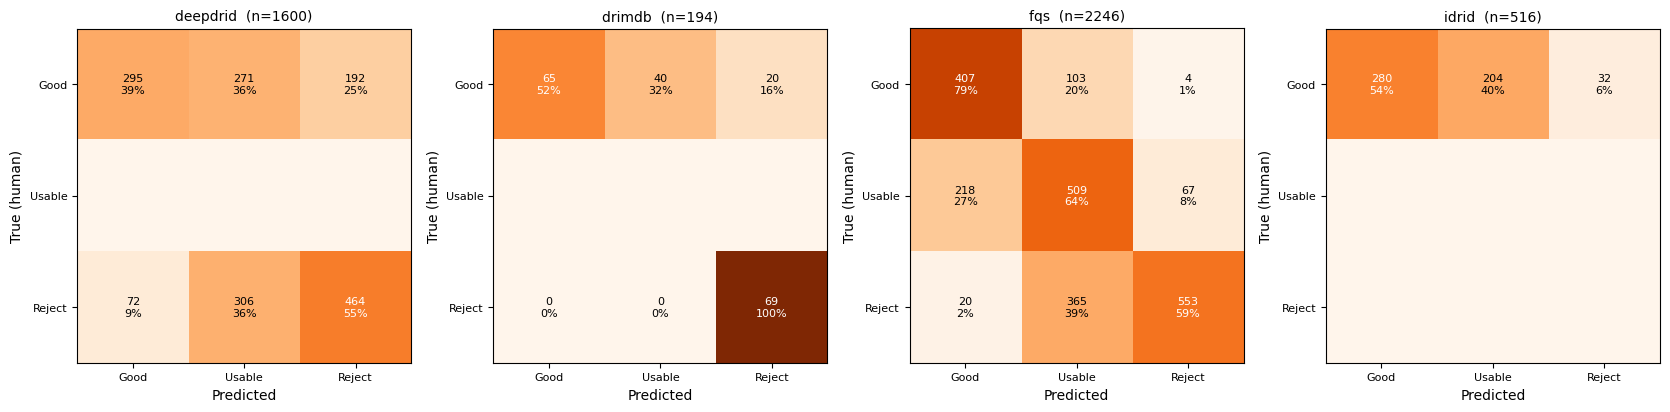

  An empty row means that dataset has no images with that human label -
  IDRiD is all good quality by construction, so its Usable and Reject rows are
  empty and only the top row is informative.


In [6]:
# ============================================================================
# CELL 6 - Confusion matrices, one panel per dataset
# ============================================================================
dsets = [d for d in sorted(scheme) if d in detail]
fig, axes = plt.subplots(1, len(dsets), figsize=(4.2 * len(dsets), 4.0))
axes = np.atleast_1d(axes)
for ax, ds in zip(axes, dsets):
    cm = np.array(detail[ds].get("confusion", detail[ds].get("confusion_3x3")))
    cmn = cm / np.maximum(cm.sum(axis=1, keepdims=True), 1)
    ax.imshow(cmn, cmap="Oranges", vmin=0, vmax=1)
    ax.set_xticks(range(3), CLASSES, fontsize=8)
    ax.set_yticks(range(3), CLASSES, fontsize=8)
    ax.set_xlabel("Predicted"); ax.set_ylabel("True (human)")
    ax.set_title(f"{ds}  (n={detail[ds]['safety']['n_reject'] if False else cm.sum()})",
                 fontsize=10)
    for i in range(3):
        for j in range(3):
            if cm[i].sum() == 0:
                continue
            ax.text(j, i, f"{cm[i, j]}\n{cmn[i, j]:.0%}", ha="center", va="center",
                    fontsize=8, color="white" if cmn[i, j] > 0.5 else "black")
plt.tight_layout(); plt.savefig(FIGURES / "confusion_external.png", dpi=150); plt.show()

print("""  An empty row means that dataset has no images with that human label -
  IDRiD is all good quality by construction, so its Usable and Reject rows are
  empty and only the top row is informative.""")

In [7]:
# ============================================================================
# CELL 7 - Do the defect heads agree with real human sub-scores?
# ============================================================================
# Week 10 measured this on DeepDRiD (defocus vs Clarity, -0.469 against a
# classical lap_var baseline of 0.120). Repeat it here across every dataset
# that carries a sub-score, so the transfer claim is not resting on one source.
LAPVAR_BASELINE = 0.120
pairs = [("defocus", "clarity", "negative"),
         ("underexposed", "clarity", "negative"),
         ("obstruction", "artifact", "positive"),
         ("off_centre", "field_def", "negative")]

trans = {}
for ds in sorted(scheme):
    sub = pred[pred.dataset == ds]
    avail = [(d, r, e) for d, r, e in pairs
             if r in sub.columns and sub[r].notna().sum() > 50]
    if not avail:
        continue
    print(f"\n{ds}  (n={len(sub)})")
    for d, real, expect in avail:
        m = sub[real].notna()
        if sub.loc[m, real].nunique() < 2 or sub.loc[m, f"sev_{d}"].nunique() < 2:
            print(f"  sev_{d:14s} vs {real:10s} one side is constant - undefined, skipped")
            continue
        p = float(sub.loc[m, f"sev_{d}"].corr(sub.loc[m, real]))
        s = float(spearmanr(sub.loc[m, f"sev_{d}"], sub.loc[m, real]).statistic)
        ok = "OK        " if ((p < 0) == (expect == "negative")) else "WRONG SIGN"
        print(f"  sev_{d:14s} vs {real:10s} pearson {p:+.3f}  spearman {s:+.3f}  "
              f"expect {expect:8s} {ok}")
        trans[f"{ds}:{d}_vs_{real}"] = {"pearson": p, "spearman": s,
                                        "n": int(m.sum()), "expected": expect}

print(f"""
  The bar, set in Week 9 before any of this was trained: a classical Laplacian
  variance predicts real human Clarity at {LAPVAR_BASELINE:+.3f}. Any learned head
  that does not beat that on an unseen dataset has added nothing over a plain
  OpenCV statistic - and that is worth reporting either way.""")

record("w11-defect-transfer-external", {"lap_var_baseline": LAPVAR_BASELINE}, trans)


deepdrid  (n=1600)
  sev_defocus        vs clarity    pearson -0.469  spearman -0.469  expect negative OK        
  sev_underexposed   vs clarity    pearson -0.283  spearman -0.213  expect negative OK        
  sev_obstruction    vs artifact   pearson +0.307  spearman +0.390  expect positive OK        
  sev_off_centre     vs field_def  pearson -0.144  spearman -0.199  expect negative OK        

  The bar, set in Week 9 before any of this was trained: a classical Laplacian
  variance predicts real human Clarity at +0.120. Any learned head
  that does not beat that on an unseen dataset has added nothing over a plain
  OpenCV statistic - and that is worth reporting either way.
recorded w11-defect-transfer-external


{'name': 'w11-defect-transfer-external',
 'when': '2026-10-13T20:43:20',
 'params': {'lap_var_baseline': 0.12},
 'metrics': {'deepdrid:defocus_vs_clarity': {'pearson': -0.46894944242838565,
   'spearman': -0.4693221558449372,
   'n': 1600,
   'expected': 'negative'},
  'deepdrid:underexposed_vs_clarity': {'pearson': -0.28348094732235296,
   'spearman': -0.2130392812719392,
   'n': 1600,
   'expected': 'negative'},
  'deepdrid:obstruction_vs_artifact': {'pearson': 0.3068831046691894,
   'spearman': 0.3900665560721829,
   'n': 1600,
   'expected': 'positive'},
  'deepdrid:off_centre_vs_field_def': {'pearson': -0.14374768377899122,
   'spearman': -0.19897336204646673,
   'n': 1600,
   'expected': 'negative'}},
 'notes': ''}

In [8]:
# ============================================================================
# CELL 8 - Can localisation be recovered?   [the one that might change a claim]
# ============================================================================
# Week 10 found Grad-CAM FLAT across all four defects - every one sat at the
# 0.43 chance level, so the model detects an eyelid at 0.995 AUC but cannot say
# where it is. Before writing that up as a hard limitation, test the obvious
# methodological suspect.
#
# We took gradients of the POST-SIGMOID output. Standard Grad-CAM uses the
# PRE-activation score, because a saturated sigmoid has vanishing gradients -
# exactly the regime a confident prediction sits in. Same weights, different
# gradient signal.
if CAM_DIR is None:
    print("cam_eval not attached - skipping. Re-publish retina-multihead with it "
          "if you want this test.")
else:
    cam_man = pd.read_csv(CAM_DIR)
    CAM_IMAGES = CAM_DIR.parent / "cam_eval"
    print(f"{len(cam_man):,} evaluation images with known defect geometry")

    # clone the defect head's weights into a LINEAR Dense -> the pre-sigmoid logit
    lin = keras.layers.Dense(len(DEFECTS), activation=None, name="defects_logit")
    lin.build(defects_layer.input.shape)
    lin.set_weights(defects_layer.get_weights())
    logit = lin(defects_layer.input)

    cam_sigmoid = keras.Model(mh.inputs, [feature_map, defects_layer.output])
    cam_logit   = keras.Model(mh.inputs, [feature_map, logit])

    # the clone must be exact, or this comparison means nothing
    probe = np.stack([decode(str(CAM_IMAGES / f)).numpy()
                      for f in cam_man.filename.head(8)])
    _, ps = cam_sigmoid.predict(probe, verbose=0)
    _, pl = cam_logit.predict(probe, verbose=0)
    err = float(np.abs(1 / (1 + np.exp(-pl)) - ps).max())
    print(f"logit clone check: max |sigmoid(logit) - model output| = {err:.2e}")
    assert err < 1e-4, "logit clone is wrong - comparison would be meaningless"

    CAM_BATCH = 16     # the tape retains every activation; 120 OOMs a T4

    def cam_of(model, images, idx, batch=CAM_BATCH):
        outs = []
        for s in range(0, len(images), batch):
            x = tf.convert_to_tensor(images[s:s + batch], dtype=tf.float32)
            with tf.GradientTape() as tape:
                fm, pr = model(x, training=False)
                tape.watch(fm)
                t = pr[:, idx]
            g = tape.gradient(t, fm)
            w = tf.reduce_mean(g, axis=(1, 2))
            c = tf.nn.relu(tf.einsum("bhwc,bc->bhw", fm, w))
            outs.append((c / (tf.reduce_max(c, axis=(1, 2), keepdims=True)
                              + 1e-8)).numpy())
        return np.concatenate(outs, axis=0)

    NULL = 3 / 7      # top 3 rows of a 7x7 grid
    top_mass = lambda c, r=3: c[:, :r, :].sum(axis=(1, 2)) / (c.sum(axis=(1, 2)) + 1e-8)

    print(f"\nnull expectation (no spatial preference): {NULL:.3f}")
    print(f"{'defect':14s} {'n':>4s} {'sigmoid':>9s} {'logit':>9s}   verdict")
    loc = {}
    for i, d in enumerate(DEFECTS):
        cand = cam_man.index[cam_man.defect == d].tolist()[:120]
        if not cand:
            continue
        imgs = np.stack([decode(str(CAM_IMAGES / cam_man.filename[j])).numpy()
                         for j in cand])
        a = top_mass(cam_of(cam_sigmoid, imgs, i)).mean()
        b = top_mass(cam_of(cam_logit,   imgs, i)).mean()
        v = ("LOCALISED by logit" if b > NULL + 0.08 and a <= NULL + 0.08 else
             "localised both ways" if b > NULL + 0.08 else
             "still flat")
        print(f"{d:14s} {len(cand):4d} {a:9.3f} {b:9.3f}   {v}")
        loc[d] = {"n": len(cand), "sigmoid": float(a), "logit": float(b), "verdict": v}

    print(f"""
  WHAT THIS DECIDES
    obstruction enters from the TOP of the frame, so it is the only defect with
    a location. If its logit column rises clearly above {NULL:.2f} while the other
    three stay flat, localisation works and the limitation in the report
    softens to "requires the pre-activation score".

    If obstruction stays flat too, the limitation is real: a 7x7 grid at 224 px
    is simply too coarse, and recovering it needs a larger input or a
    segmentation head - both out of scope. Report it as measured.

    The other three SHOULD stay flat. Blur and exposure are global; off-centre
    moves in a random direction per image. A flat score there is the model
    being correct, not failing.""")

    record("w11-localisation-logit-test",
           {"grid": 7, "rows": 3, "null": NULL, "cam_batch": CAM_BATCH},
           loc, notes="post-sigmoid vs pre-activation Grad-CAM on the same weights")

340 evaluation images with known defect geometry


2026-10-13 20:43:27.198427: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:27.334509: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:27.645783: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:27.787049: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-13 20:43:28.544472: E external/local_xla/xla/stream_

logit clone check: max |sigmoid(logit) - model output| = 5.96e-08

null expectation (no spatial preference): 0.429
defect            n   sigmoid     logit   verdict
underexposed    120     0.409     0.409   still flat
defocus          87     0.430     0.430   still flat
obstruction      69     0.414     0.414   still flat
off_centre       64     0.435     0.435   still flat

  WHAT THIS DECIDES
    obstruction enters from the TOP of the frame, so it is the only defect with
    a location. If its logit column rises clearly above 0.43 while the other
    three stay flat, localisation works and the limitation in the report
    softens to "requires the pre-activation score".

    If obstruction stays flat too, the limitation is real: a 7x7 grid at 224 px
    is simply too coarse, and recovering it needs a larger input or a
    segmentation head - both out of scope. Report it as measured.

    The other three SHOULD stay flat. Blur and exposure are global; off-centre
    moves in a random d

In [9]:
# ============================================================================
# CELL 9 - Save and list what to publish
# ============================================================================
for junk in [".virtual_documents"]:
    shutil.rmtree(WORK / junk, ignore_errors=True)

print("files to publish:")
for p in sorted(WORK.iterdir()):
    if p.is_dir():
        print(f"   {p.name + '/':34s} {len(list(p.iterdir()))} files")
    else:
        print(f"   {p.name:34s} {p.stat().st_size / 1e6:7.2f} MB")

!du -sh /kaggle/working

eyeq_rag = 0.006
ext_rows = summary[summary.dataset != "EyeQ (internal)"]
worst = ext_rows.loc[ext_rows.reject_as_good.idxmax()] if ext_rows.reject_as_good.notna().any() else None

print(f"""
{'='*70}
SUMMARY FOR VERIFICATION - paste this block back to me
{'='*70}""")
print(summary.to_string(index=False, float_format=lambda v: f"{v:.3f}"))
if worst is not None:
    print(f"\nworst reject-as-good : {worst.dataset} at {worst.reject_as_good:.1%} "
          f"(EyeQ internal {eyeq_rag:.1%})")
if CAM_DIR is not None and 'loc' in dir():
    print("localisation         : " + "; ".join(
        f"{k} {v['sigmoid']:.3f}->{v['logit']:.3f}" for k, v in loc.items()))
print(f"{'='*70}")

files to publish:
   __notebook__.ipynb                    0.14 MB
   figures/                           1 files
   predictions_external.csv              0.54 MB
   results/                           3 files
776K	/kaggle/working

SUMMARY FOR VERIFICATION - paste this block back to me
        dataset     n            scheme  accuracy  macro_f1  kappa  reject_as_good                                   acc_ci
EyeQ (internal) 16249           3-class     0.883     0.867  0.900           0.006                                      NaN
       deepdrid  1600            binary     0.644     0.642  0.294           0.086                      [0.62125, 0.666875]
         drimdb   194            binary     0.897     0.893  0.789           0.000 [0.8505154639175257, 0.9381443298969072]
            fqs  2246           3-class     0.654     0.662  0.689           0.021 [0.6340160284951024, 0.6732079252003562]
          idrid   516 control (1 class)       NaN       NaN    NaN             NaN             

---

## AFTER IT RUNS — outputs to save

### 1 · Publish as a new Kaggle Dataset

**Save Version → Save & Run All → Output tab → New Dataset**, named exactly:

```
retina-generalisation
```

| File / folder | Why it is kept |
|---|---|
| `predictions_external.csv` | Every external image with its predicted gradability, the three class probabilities, four defect severities and its human labels. One file answers most follow-up questions without re-running anything. |
| `results/w11-generalisation.json` | Per-dataset metrics, confusion matrices and safety numbers. |
| `results/w11-defect-transfer-external.json` | Defect heads against real sub-scores, across every dataset that has them. |
| `results/w11-localisation-logit-test.json` | The post-sigmoid vs pre-activation comparison. |
| `figures/confusion_external.png` | Report figure. |

### 2 · Paste the SUMMARY block back to me

Cell 9 prints it. Send that plus anything that errored.

**The three numbers I will be looking at:**

- **`reject_as_good` per dataset.** On EyeQ it is 0.6%. If it holds near that on
  unseen cameras, the safety property travels — that is the strongest possible
  generalisation result. If it jumps, that is the headline finding and it goes in the
  report plainly.
- **Any 3-class dataset's macro-F1** against the EyeQ 0.867. The gap is your domain
  shift, measured rather than asserted.
- **`obstruction` in the localisation row.** If the logit column clears 0.43 while the
  other three stay flat, the Week 13 deck's localisation slide changes from a
  limitation to a result.

### 3 · Then Week 12 attaches

`retina-multihead` + `retina-generalisation`. No large datasets.

---

### If something goes wrong

| Symptom | Cause |
|---|---|
| Cell 1 `FileNotFoundError` | That dataset is not attached; the message names it |
| Cell 2 `StopIteration` on pooling | Wrong checkpoint — you want `retina_multihead.keras` |
| Cell 2 shows a dataset with unexpected `quality` values | Not a bug. Cell 5 branches on it; just tell me what it printed |
| Cell 8 skipped | `cam_eval/` was not in the published `retina-multihead` |
| Cell 8 asserts on the logit clone | The defect head was renamed; send me cell 2's layer list |
| OOM in cell 8 | Lower `CAM_BATCH` from 16 to 8 |

**Do not delete a failing assertion.** Send me the output — each one guards something
that otherwise fails silently.